# Etapa 1: Análise exploratória (EDA)

**Objetivo:** entender os dados antes de modelar. Queremos descobrir que estrutura existe na relação entre os atributos e a nota, principalmente aquela que **uma regressão linear nos atributos brutos não consegue capturar**. É essa estrutura que vai permitir superar a referência de RMSE ≈ 0,84.

**Perguntas que guiam a análise**

1. Como as notas se distribuem?
2. Como os atributos se distribuem? Há algum cuidado necessário (escalas, dependências entre colunas)?
3. Quais atributos se relacionam com a nota, e de que forma (linear ou não)?
4. As médias do usuário e do filme são igualmente confiáveis, qualquer que seja o número de notas por trás delas?
5. O gosto do usuário por gênero interage com o gênero do filme?
6. O que a regressão linear bruta deixa nos resíduos?

> Toda a análise usa **apenas o conjunto de treino**. O teste nunca é olhado para tomar decisões (ver Etapa 2).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)
# O BLAS do macOS emite avisos espúrios de overflow no produto matricial; os resultados não são afetados.
warnings.filterwarnings("ignore", category=RuntimeWarning, module="sklearn")

df = pd.read_csv("../data/train.csv")
y = df["stars"]
df.head()

,pair_id,user_avg_stars,user_n_ratings,age,share_action,share_comedy,share_drama,movie_avg_stars,movie_n_ratings,genre,release_year,stars
0,P00001,2.99,15,48,0.315,0.501,0.184,3.61,71,drama,2012,3
1,P00002,3.44,35,57,0.180,0.151,0.669,3.15,35,action,2015,2
2,P00003,3.91,46,27,0.701,0.258,0.041,2.72,36,action,1982,4
3,P00004,4.23,23,18,0.700,0.204,0.096,3.26,29,action,2021,5
4,P00005,3.54,29,16,0.621,0.257,0.122,2.83,11,action,2002,4


## 1. Visão geral

São 4000 linhas, 10 atributos, um identificador (`pair_id`, que **não** deve ser usado como atributo) e o alvo `stars`.

In [2]:
print(df.shape)
print("valores faltantes:", df.isna().sum().sum())
df.describe().T

(4000, 12)
valores faltantes: 0


,count,mean,std,min,25%,50%,75%,max
user_avg_stars,4000.0,3.337,0.710,1.040,2.840,3.340,3.800,5.000
user_n_ratings,4000.0,58.524,86.287,3.000,14.000,27.000,60.000,1016.000
age,4000.0,36.529,14.000,16.000,24.000,36.000,47.000,79.000
share_action,4000.0,0.390,0.191,0.043,0.237,0.367,0.533,0.867
share_comedy,4000.0,0.295,0.116,0.058,0.208,0.280,0.370,0.722
share_drama,4000.0,0.315,0.209,0.031,0.134,0.238,0.510,0.838
movie_avg_stars,4000.0,3.012,0.755,0.310,2.510,3.010,3.530,5.000
movie_n_ratings,4000.0,55.055,69.895,5.000,17.000,34.000,66.000,1345.000
release_year,4000.0,2004.126,15.020,1970.000,1993.000,2007.500,2017.000,2024.000
stars,4000.0,3.459,1.166,0.000,3.000,4.000,4.000,5.000


## 2. A variável alvo: `stars`

Vale entender o alvo antes de qualquer outra coisa:
- Ele é **discreto** (0 a 5) e **ordinal** (4 é melhor que 3), mas vamos prever números reais. Com o RMSE, prever 3,6 quando a nota provável é 3 ou 4 é melhor do que "arredondar".
- Ele é **limitado** a [0, 5]. Um modelo linear pode prever valores fora desse intervalo, e veremos que isso acontece.
- A previsão constante (sempre a média) tem RMSE igual ao **desvio padrão** de `stars`. É o pior patamar razoável.

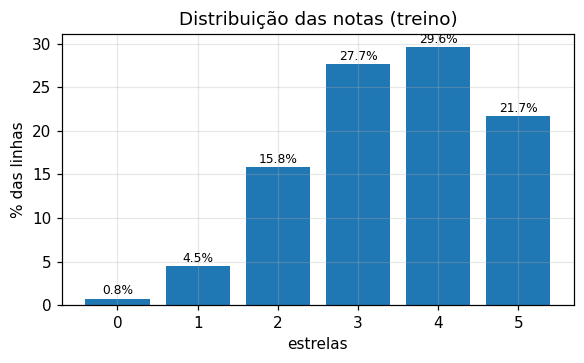

média = 3.459 | desvio padrão = 1.165 -> RMSE da previsão constante ≈ 1.165


In [3]:
freq = y.value_counts(normalize=True).sort_index()
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(freq.index, freq.values * 100, color="C0")
ax.set(xlabel="estrelas", ylabel="% das linhas", title="Distribuição das notas (treino)")
for k, v in freq.items():
    ax.text(k, v * 100 + 0.5, f"{v:.1%}", ha="center", fontsize=8)
plt.show()

rmse_const = np.sqrt(((y - y.mean()) ** 2).mean())
print(f"média = {y.mean():.3f} | desvio padrão = {y.std(ddof=0):.3f} -> RMSE da previsão constante ≈ {rmse_const:.3f}")

**Leitura:** a distribuição é assimétrica à esquerda. A maior parte das notas está entre 3 e 5, e notas 0 e 1 são raras. Os números batem com o enunciado (média 3,46 e desvio 1,17).

## 3. Os atributos

### 3.1 Distribuições

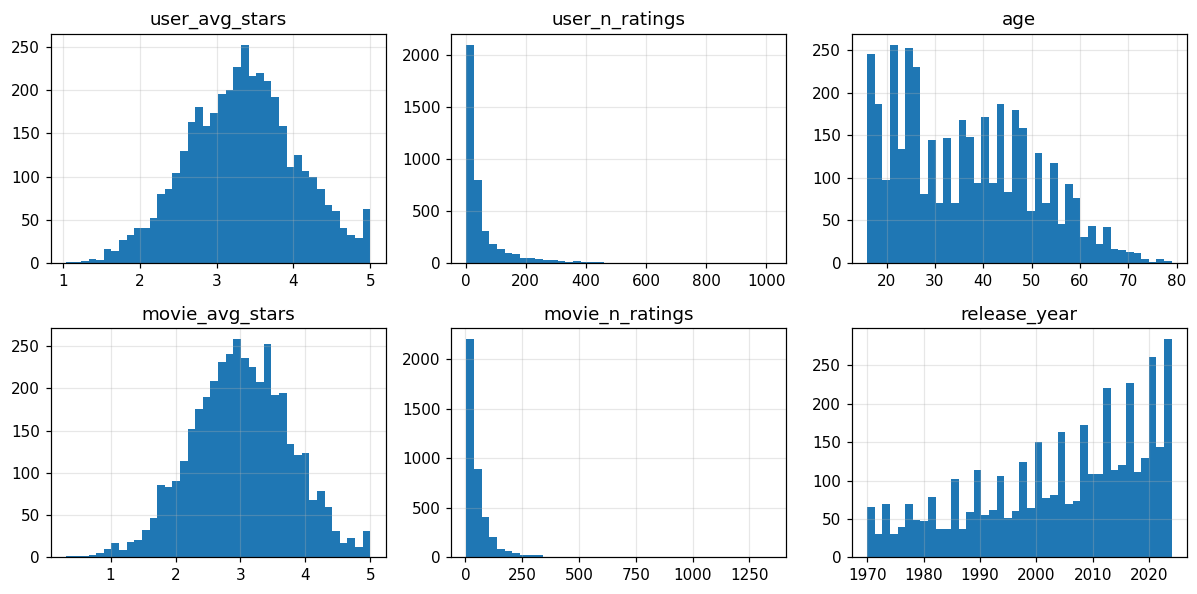

genre
action    1462
drama     1284
comedy    1254
Name: count, dtype: int64

In [4]:
cols = ["user_avg_stars", "user_n_ratings", "age", "movie_avg_stars", "movie_n_ratings", "release_year"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, c in zip(axes.ravel(), cols):
    ax.hist(df[c], bins=40, color="C0")
    ax.set_title(c)
plt.tight_layout()
plt.show()
df["genre"].value_counts()

**Leitura**
- `user_n_ratings` e `movie_n_ratings` têm **cauda longa à direita**: a maioria tem dezenas de notas e poucos têm centenas ou milhares. Uma transformação logarítmica, `log(n)`, deixa essas escalas mais manejáveis.
- As médias (`user_avg_stars`, `movie_avg_stars`) são aproximadamente simétricas, em torno de 3,3 e 3,0.
- Os três gêneros estão razoavelmente balanceados.

### 3.2 Um cuidado: as três `share_*` somam 1

Como `share_action + share_comedy + share_drama = 1` em todas as linhas, qualquer uma delas é determinada pelas outras duas. Na regressão linear (com intercepto), isso cria **colinearidade perfeita**: a matriz $X^\top X$ não é invertível e os coeficientes deixam de ser identificáveis. Por isso **descartamos uma das três** ao montar a matriz de atributos. A informação é a mesma.

In [5]:
soma = df[["share_action", "share_comedy", "share_drama"]].sum(axis=1)
print("soma mínima:", soma.min().round(3), "| soma máxima:", soma.max().round(3))

soma mínima: 0.999 | soma máxima: 1.001


## 4. Quais atributos se relacionam com a nota?

A correlação linear de Pearson é um primeiro filtro. Ela só mede relações **lineares**, então uma correlação baixa não quer dizer que o atributo seja inútil.

In [6]:
num = df.drop(columns=["pair_id", "genre"])
num.corr()["stars"].drop("stars").sort_values(key=abs, ascending=False).to_frame("correlação com stars")

,correlação com stars
movie_avg_stars,0.521
user_avg_stars,0.455
share_action,0.114
share_drama,-0.111
user_n_ratings,-0.104
age,-0.099
release_year,0.036
share_comedy,0.011
movie_n_ratings,0.005


As duas médias são, de longe, os atributos mais correlacionados com a nota. Isso faz sentido: um usuário generoso e um filme bem avaliado puxam a nota para cima.

Abaixo vemos a **nota média por faixa** de cada atributo. É uma forma simples de enxergar se a relação é linear.

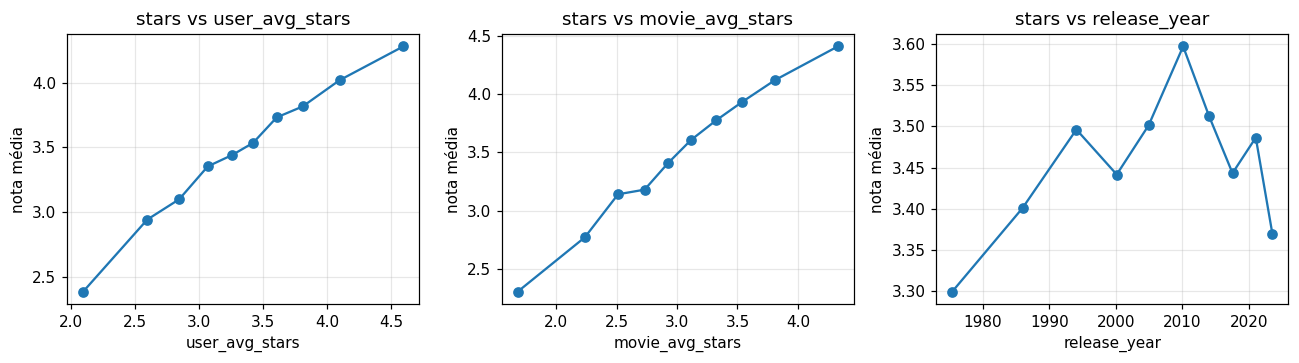

correlação entre user_avg_stars e movie_avg_stars: 0.002


In [7]:
def media_por_faixa(x, y, bins=10):
    g = y.groupby(pd.qcut(x, bins, duplicates="drop"), observed=True)
    return g.apply(lambda s: x[s.index].mean()), g.mean()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, c in zip(axes, ["user_avg_stars", "movie_avg_stars", "release_year"]):
    xm, ym = media_por_faixa(df[c], y)
    ax.plot(xm, ym, "o-")
    ax.set(xlabel=c, ylabel="nota média", title=f"stars vs {c}")
plt.tight_layout()
plt.show()

print("correlação entre user_avg_stars e movie_avg_stars:",
      np.corrcoef(df.user_avg_stars, df.movie_avg_stars)[0, 1].round(3))

**Leitura**
- A nota cresce de forma quase linear com cada média, mas **achata nos extremos**. É o efeito de teto/piso: o alvo está preso em [0, 5], então quem já tem média alta não pode subir indefinidamente.
- As duas médias são **praticamente independentes** entre si (correlação ≈ 0). Cada uma traz informação nova.

## 5. As médias são confiáveis? O papel de `n`

Uma média calculada com 3 notas é muito mais ruidosa do que uma com 500. Se for assim, o modelo deveria **confiar menos** em `user_avg_stars` quando `user_n_ratings` é pequeno, e o mesmo vale para o filme.

Teste: dividimos os dados em quartis de `n` e ajustamos a inclinação de `stars` contra a média em cada quartil. Se as médias com poucas notas forem ruidosas, a inclinação deve **crescer com n**.

In [8]:
linhas = []
for media, n in [("user_avg_stars", "user_n_ratings"), ("movie_avg_stars", "movie_n_ratings")]:
    quartil = pd.qcut(df[n], 4, labels=["Q1 (n pequeno)", "Q2", "Q3", "Q4 (n grande)"])
    for q, g in df.groupby(quartil, observed=True):
        inclinacao = np.polyfit(g[media], g["stars"], 1)[0]
        linhas.append({"média": media, "quartil de n": q, "inclinação": inclinacao})
pd.DataFrame(linhas).pivot(index="quartil de n", columns="média", values="inclinação")

média,movie_avg_stars,user_avg_stars
quartil de n,,
Q1 (n pequeno),0.754,0.709
Q2,0.799,0.735
Q3,0.848,0.677
Q4 (n grande),0.820,0.838


**Leitura:** a inclinação tende a ser maior quando `n` é grande, como esperado, mas o efeito é **modesto** e não é monótono no caso do usuário. Vale testar o **encolhimento** (*shrinkage*) das médias na Etapa 3, mas não deve ser aí que está o grande ganho:

$$\text{média encolhida} = \frac{n \cdot \text{média} + k \cdot \text{média global}}{n + k}$$

Com poucas notas, a média é puxada para a média global. Com muitas, fica quase igual à original. O valor de $k$ é um hiperparâmetro, a ser escolhido por validação.

## 6. Afinidade de gênero: o gosto do usuário encontra o gênero do filme

Cada usuário tem as proporções `share_action`, `share_comedy` e `share_drama` no seu histórico, e cada filme tem um `genre`. A hipótese natural é que **quem assiste muito um gênero tende a dar notas mais altas a filmes desse gênero**.

Na regressão linear bruta, `share_drama` entra com **o mesmo coeficiente para qualquer filme**, seja drama ou ação. Ela não tem como representar "share_drama importa *quando o filme é drama*". Isso é uma **interação** entre `genre` e `share_*`.

Para capturá-la, criamos o atributo **afinidade**: o `share` do gênero do próprio filme.

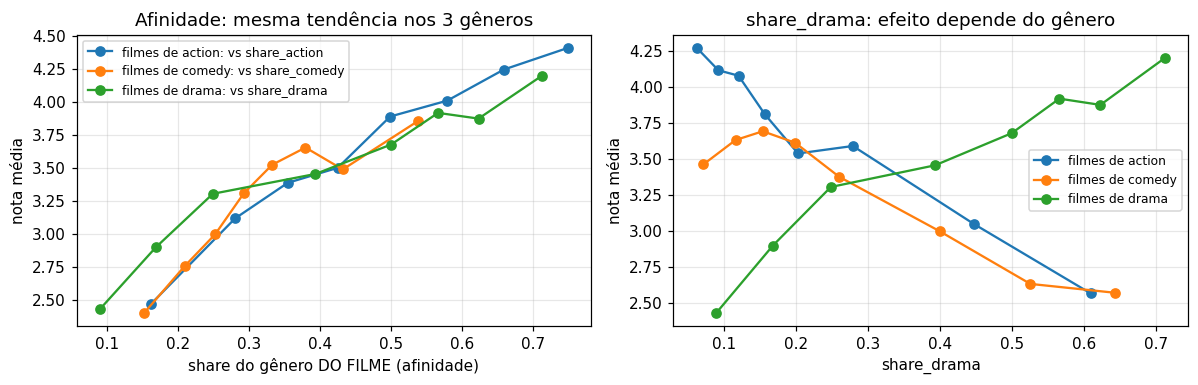

correlação affinity x stars: 0.469


In [9]:
df["affinity"] = np.select(
    [df.genre == "action", df.genre == "comedy"],
    [df.share_action, df.share_comedy],
    default=df.share_drama,
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for g in ["action", "comedy", "drama"]:
    sub = df[df.genre == g]
    xm, ym = media_por_faixa(sub[f"share_{g}"], sub.stars, 8)
    axes[0].plot(xm, ym, "o-", label=f"filmes de {g}: vs share_{g}")
    xm, ym = media_por_faixa(sub["share_drama"], sub.stars, 8)
    axes[1].plot(xm, ym, "o-", label=f"filmes de {g}")
axes[0].set(xlabel="share do gênero DO FILME (afinidade)", ylabel="nota média", title="Afinidade: mesma tendência nos 3 gêneros")
axes[1].set(xlabel="share_drama", ylabel="nota média", title="share_drama: efeito depende do gênero")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print("correlação affinity x stars:", np.corrcoef(df.affinity, y)[0, 1].round(3))

**Leitura (achado mais importante da EDA)**
- Gráfico da esquerda: nos três gêneros, a nota sobe com a afinidade, de forma parecida. A correlação da afinidade com a nota (≈ 0,47) é comparável à das médias. Nenhum dos atributos brutos `share_*` chegava perto disso (|r| ≈ 0,11).
- Gráfico da direita: `share_drama` **aumenta** a nota em filmes de drama e **diminui** em filmes de ação. O efeito muda de sinal conforme o gênero. Uma regressão linear bruta só pode estimar um coeficiente médio para `share_drama`, que fica perto de zero, e perde o efeito.
- A curva da afinidade não é uma reta: ela é mais íngreme para afinidade baixa. Um termo quadrático ou um spline pode ajudar.

## 7. O que a regressão linear bruta deixa para trás

Uma forma útil de procurar estrutura que falta é olhar os **resíduos** $y - \hat y$ da regressão linear nos atributos brutos. Se o modelo estivesse capturando tudo o que é sistemático, a média dos resíduos seria ≈ 0 em qualquer faixa de qualquer atributo. Padrões nos resíduos indicam **viés** do modelo, ou seja, estrutura que o conjunto de hipóteses linear não consegue representar.

Para não enganar a nós mesmos com o erro dentro da amostra ($E_{in}$), usamos previsões **fora da dobra** (validação cruzada com 5 dobras). Cada previsão vem de um modelo que não viu aquela linha.

RMSE (validação cruzada) da regressão linear bruta: 0.828
previsões entre 0.62 e 6.07


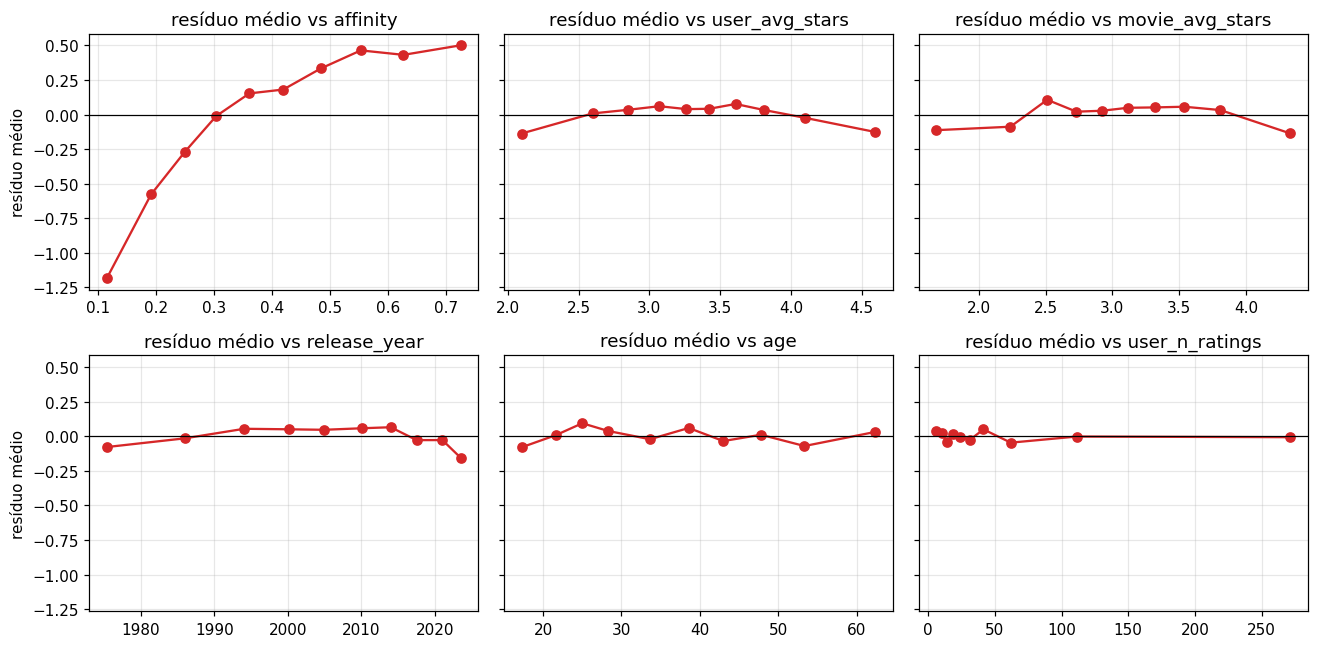

In [10]:
X_raw = pd.get_dummies(df.drop(columns=["pair_id", "stars", "affinity"]), drop_first=True).astype(float)
X_raw = X_raw.drop(columns=["share_drama"])  # colinearidade perfeita (seção 3.2)

kf = KFold(n_splits=5, shuffle=True, random_state=0)
pred_raw = cross_val_predict(LinearRegression(), X_raw, y, cv=kf)
res = y - pred_raw
print(f"RMSE (validação cruzada) da regressão linear bruta: {np.sqrt((res**2).mean()):.3f}")
print(f"previsões entre {pred_raw.min():.2f} e {pred_raw.max():.2f}")

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for ax, c in zip(axes.ravel(), ["affinity", "user_avg_stars", "movie_avg_stars", "release_year", "age", "user_n_ratings"]):
    xm, rm = media_por_faixa(df[c], res, 10)
    ax.plot(xm, rm, "o-", color="C3")
    ax.axhline(0, color="k", lw=0.8)
    ax.set(title=f"resíduo médio vs {c}")
axes[0, 0].set_ylabel("resíduo médio"); axes[1, 0].set_ylabel("resíduo médio")
plt.tight_layout()
plt.show()

**Leitura**
- O RMSE de validação da linear bruta (≈ 0,83) reproduz a referência do enunciado (≈ 0,84). É uma boa checagem de sanidade.
- **Afinidade:** é o padrão mais forte de todos. Com afinidade baixa, o modelo **superestima** a nota em mais de 1 estrela; com afinidade alta, subestima. É exatamente a interação da seção 6, que o modelo bruto não vê.
- **Médias, ano e idade:** há uma leve "corcova" (resíduo negativo nos extremos). Ela é coerente com o **efeito de teto/piso** da seção 4 e com efeitos não lineares pequenos.
- As previsões saem de [0, 5]. Só **cortar as previsões em [0, 5]** já reduz o erro, e um modelo que respeite os limites do alvo deve ir ainda melhor.

## 8. Evidência preliminar: quanto vale cada achado?

Para checar se os achados importam de verdade, medimos o RMSE de validação cruzada ao acrescentar cada ideia à regressão linear. **Isto ainda não é o protocolo final** (ele vem na Etapa 2, com dobras repetidas e desvio padrão), mas já mostra a ordem de grandeza.

In [11]:
def rmse_cv(X, clip=False):
    p = cross_val_predict(LinearRegression(), X, y, cv=kf)
    if clip:
        p = np.clip(p, 0, 5)
    return np.sqrt(((y - p) ** 2).mean())

X1 = X_raw.assign(affinity=df.affinity)
X2 = X1.assign(affinity2=df.affinity ** 2)
tabela = pd.Series({
    "constante (média)": rmse_const,
    "linear bruta": rmse_cv(X_raw),
    "+ afinidade": rmse_cv(X1),
    "+ afinidade²": rmse_cv(X2),
    "+ afinidade² e corte em [0, 5]": rmse_cv(X2, clip=True),
    "oráculo (enunciado)": 0.39,
}, name="RMSE (CV 5 dobras)")
tabela.to_frame()

,RMSE (CV 5 dobras)
constante (média),1.165
linear bruta,0.828
+ afinidade,0.663
+ afinidade²,0.631
"+ afinidade² e corte em [0, 5]",0.619
oráculo (enunciado),0.390


## 9. Conclusões da EDA

| # | Achado | Implicação para a modelagem |
|---|---|---|
| 1 | As médias do usuário e do filme são os preditores mais fortes e são independentes entre si | Base de qualquer modelo |
| 2 | **Afinidade de gênero** (share do gênero do filme) é uma interação forte que a linear bruta não enxerga | Criar o atributo `affinity`. Só ele leva o RMSE de ≈ 0,83 para ≈ 0,66 |
| 3 | O efeito da afinidade não é linear | Termos polinomiais, splines ou modelos não paramétricos |
| 4 | O alvo é limitado em [0, 5], com efeito de teto/piso nos extremos | Cortar as previsões e considerar modelos que respeitem os limites (por exemplo, ordinais) |
| 5 | As `share_*` somam 1 | Descartar uma delas nos modelos lineares |
| 6 | Médias com poucas notas são um pouco menos informativas | Testar o encolhimento das médias e `log(n)`, com ganho esperado pequeno |
| 7 | Idade e ano têm efeitos fracos e possivelmente não lineares | Testar splines e interações com gênero, sempre validando |

**Em termos do curso:** a linear bruta tem **viés** alto, porque o seu conjunto de hipóteses não contém a interação gênero × gosto nem as curvaturas. A engenharia de atributos aumenta a expressividade do modelo e reduz o viés. A pergunta das próximas etapas é **até onde** dá para aumentar a complexidade antes que a **variância** (o sobreajuste) passe a dominar. Ainda há uma boa distância entre ≈ 0,62 e o piso de ≈ 0,39.

**Próximo passo:** Etapa 2, com o protocolo de validação formal (dobras fixas e repetidas, média ± desvio) que será usado para comparar todos os modelos.